calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


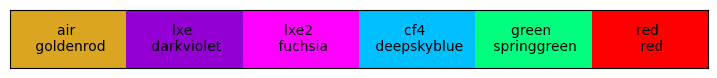

In [1]:
import numpy as np

import sys
sys.path.append('..')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PNJunction import * 

# import TemperatureCorrections as TC

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
ms.SetMPLcolors()

rad2deg = 180/np.pi

---
#### Blatt Bardeen Hall equation (BDH) 

$$ \alpha(E_\gamma) \propto (E_\gamma - E_g - E_{ph})^2 (1 - E_{ph}/(E_\gamma - E_g)) $$

$$\alpha(E_\gamma) = A(E_\gamma - E_g - E_{ph})^n$$



---
#### DM paper - modified BDH equation

$$ \alpha(E_\gamma) = \sigma_{PE}(T) \rho_{Si} = \sum_{i,j=1,2} C_i A_j \bigg[\frac{(E_\gamma - E_{g,j}(T) - E_{p,i})^2}{e^{E_{p,i}/kT} - 1} +  \frac{(E_\gamma - E_{g,j}(T) + E_{p,i})^2}{1 - e^{-E_{p,i}/kT}} \bigg] + A_d \sqrt{E_\gamma - E_{gd}(T)} $$

$$ \text{abs = indirect1((absorpPhonon1 + emitPhonon1) + (absorpPhonon2 + emitPhonon2)) + indirect2(...) + direct}$$

$$ E_g(T) = E_g(0) - \frac{\beta T^2}{T + \gamma} $$

$$C_i \text{- electron-phonon coupling constant}$$
$$ C_{TA} = 5.5 $$
$$ C_{TO} = 4.0 $$

In [2]:
## DM paper - Stanford

Ephonons = np.array([18.27, 57.73])*1e-3 # meV
# transverse acoustic, optical
# TA - 212 kelvin
Eph_ta = Ephonons[0]
Cta = 5.5

# TO - 675 K (from Solar Cells paper)
Eph_to = Ephonons[1]
Cto = 4.0

betaL = 7.021e-4 # eV/K
gammaL = 1108.0 # K

# first bandgap (temp dependance)

Eg_01 = 1.134 # eV
c0 = 325 # eV-2/cm
c1 = 1.7e-3 # 1/K
A1 = lambda T:  c0*np.exp(-c1*T)

# no temp dependance on constants
Eg_02 = 2.5 # eV
A2 = 6.0e3 # eV^-2/cm

# direct bandgap (from solar cell paper)
Egd_0 = 3.2
Ad = 1.052e6 # eV^-2/cm

In [3]:
k = 8.617333262145e-5  # Boltzmann constant in eV/K
rho_Si = 2.329  # Density of Silicon in g/cm^3

def Fbandgap(Eg0, T, beta=betaL, gamma=gammaL):
    return Eg0 - beta*T**2/(T+gamma)

def PhononTerm(Egam, T, EgN, Ephonon, Cph):
    
    absorption = Cph * (Egam - EgN + Ephonon)**2/(np.exp(Ephonon/(k*T)) - 1)
    emission = Cph * (Egam - EgN - Ephonon)**2 /(1 - np.exp(-Ephonon/(k*T)))
    
    # absorbtion only condition
    Edif = Egam - EgN
    
    # conditions = [Egam < EgN - Ephonon, Edif < Ephonon, Edif >= Ephonon]
    conditions = [Egam < EgN - Ephonon, (Egam > EgN-Ephonon) & (Egam < EgN + Ephonon), Egam >= EgN + Ephonon]
    
    # conditions = [Egam < EgN - Ephonon, (Egam >= EgN-Ephonon) & (Egam <= EgN), Egam > EgN]
    outputs = [0, absorption, absorption + emission]
    
    # outputs = [absorption+emission, absorption+emission, absorption + emission]
    
    return np.select(conditions, outputs)
        
def alpha(E_gamma, T, includeDirect = True, fixDirectBandGap =  False): # units of 1/cm
    
    Eg1 = Fbandgap(Eg0=Eg_01, T=T)
    A1t = A1(T)
    
    Eg2 = Fbandgap(Eg0=Eg_02, T=T)
    A2t = A2
    
    # A1fixed =  3.231e2 # eV-2/cm
    # A2fixed =
    
    # bandgap 1, TA phonon
    g1ta = PhononTerm(E_gamma, T, Eg1, Eph_ta, Cta)
    # bandgap 1, TO phonon
    g1to = PhononTerm(E_gamma, T, Eg1, Eph_to, Cto)
    bg1 = A1t * (g1ta + g1to)
    
    # bandgap 2, TA phonon
    g2ta = PhononTerm(E_gamma, T, Eg2, Eph_ta, Cta)
    # bandgap 2, TO phonon
    g2to = PhononTerm(E_gamma, T, Eg2, Eph_to, Cto)
    bg2 = A2t * (g2ta + g2to)
    
    # doing direct bandgap
    # Egdt = Fbandgap(Eg0=4.34, T=T, beta=3.91e-4, gamma=125) # from ioffe webpage
    
    Egd_new = 3.2 #eV
    Edirect = Fbandgap(Eg0=Egd_new, T=T)
    if fixDirectBandGap:
        Edirect = Egd_new
    Adnew = 2.3e7
    fDirect = lambda Ephoton: Adnew * (Ephoton - Edirect)**1.5 / Ephoton # new function, values from older paper (bucher, bruns, wagemann)
    mask = E_gamma >= Edirect
    direct_cutoff = np.zeros_like(E_gamma)
    direct_cutoff[mask] = float(includeDirect) * fDirect(E_gamma[mask])
    
    return bg1 + bg2 + direct_cutoff, A1t*g1ta, A1t*g1to, A2t*g2ta, A2t*g2to, direct_cutoff, Edirect
    

4.3048785964912275


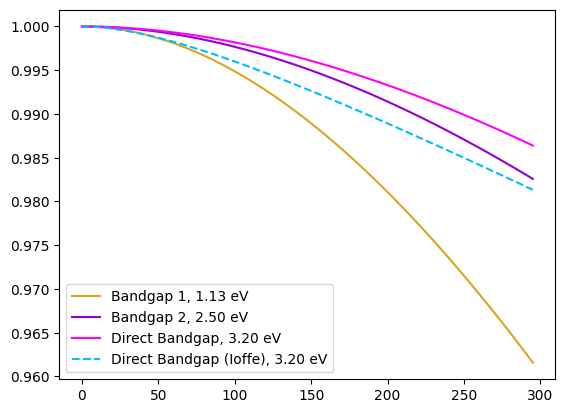

In [4]:
temps = np.arange(0, 300, 5)
Eg1 = Fbandgap(Eg0=Eg_01, T=temps)
Eg2 = Fbandgap(Eg0=Eg_02, T=temps)
Egd = Fbandgap(Eg0=Egd_0, T=temps)
Egd_ioffe = Fbandgap(Eg0=4.34, T=temps, beta=3.91e-4, gamma=125)

plt.plot(temps, Eg1/Eg_01, label=f'Bandgap 1, {Eg_01:0.2f} eV')
plt.plot(temps, Eg2/Eg_02, label=f'Bandgap 2, {Eg_02:0.2f} eV')
plt.plot(temps, Egd/Egd_0, label=f'Direct Bandgap, {Egd_0:0.2f} eV')
plt.plot(temps, Egd_ioffe/4.34, linestyle = "--", label=f'Direct Bandgap (Ioffe), {Egd_0:0.2f} eV')

plt.legend()

print(Fbandgap(Eg0=4.34, T=160, beta=3.91e-4, gamma=125))

ephoton: 1273.301737756714
g1: 0.0
g2: 0.0
direct: 0.0
full: 0.0


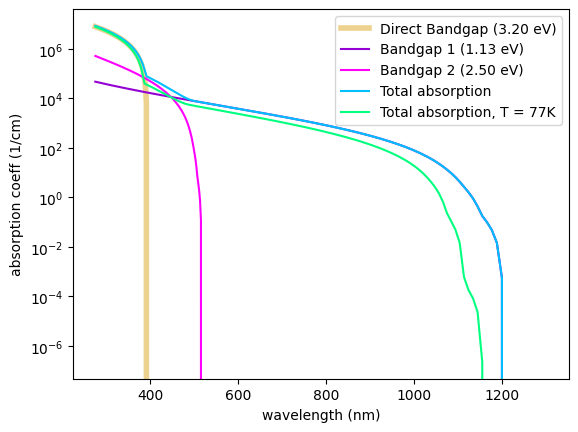

In [5]:
import numpy as np
hc = 1240 # eV nm
ephoton = np.arange(hc/1300, 4.5, 0.01)

Trt = 300
Tln2 = 77

alphaCoeff, g1ta, g1to, g2ta, g2to, direct, _ = alpha(ephoton, Trt, includeDirect=True)

# print(alphaCoeff - (g1ta + g1to + g2ta + g2to + direct))
print("ephoton:", (hc/ephoton)[2])
print("g1:", (g1ta + g1to)[2])
print("g2:", (g2ta + g2to)[2])
print("direct:", direct[2])
print("full:", alphaCoeff[2])

alphaLN2, *_ = alpha(ephoton, Tln2, includeDirect=True)

plt.semilogy(hc/ephoton, (direct), linewidth=4, alpha=0.5, label=f'Direct Bandgap ({Egd_0:0.2f} eV)')


plt.semilogy(hc/ephoton, (g1ta + g1to), label=f'Bandgap 1 ({Eg_01:0.2f} eV)')
# plt.semilogy(hc/ephoton, (g1ta), linestyle = "--", label='gap 1, TA')
# plt.semilogy(hc/ephoton, (g1to), linestyle = "--", label='gap1, TO')

plt.semilogy(hc/ephoton, (g2to + g2ta), label=f'Bandgap 2 ({Eg_02:0.2f} eV)')
# plt.semilogy(hc/ephoton, (g2ta), linestyle = "--", label='gap 2, TA')
# plt.semilogy(hc/ephoton, (g2to), linestyle = "--", label='gap 2, TO')
plt.semilogy(hc/ephoton, alphaCoeff, label='Total absorption')

# plt.semilogy(hc/ephoton, (alphaCoeff - (g1ta + g1to + g2ta + g2to + direct)), label=f'Total absorption, SUM')

plt.semilogy(hc/ephoton, alphaLN2, label=f'Total absorption, T = {Tln2}K')

# min_index = np.argmin(alphaCoeff)
# min_ephoton = ephoton[min_index]
# print(min_ephoton)
# print(Fbandgap(Eg0=Eg_02, T=Trt))


plt.ylabel("absorption coeff (1/cm)")
plt.xlabel("wavelength (nm)")

plt.legend()

In [6]:
import pandas as pd
# Load the data into a DataFrame
data = "dmpaper_supplements/pexsec_experimental_results.txt"
df = pd.read_csv(data, sep='\t')

# Print the headers
names = df.columns
print(names)
colT = names[0]
colEph = names[1]
colSigma = names[4]
print("temps:", df[colT].unique())
print("max Eph:", df[colEph].max())
dfRT = df[(df[colT] > 50) & (df[colT] < 250)]
dfRT = df

Index(['Temperature (K)', 'Energy (eV)', 'Energy Error (Lower Bound) (eV)',
       'Energy Error (Upper Bound) (eV)',
       'Photoelectric Absorption Cross Section (cm^2/g)',
       'Photoelectric Absorption Cross Section Error (cm^2/g)'],
      dtype='object')
temps: [  0.5   5.   77.  295. ]
max Eph: 2.7679


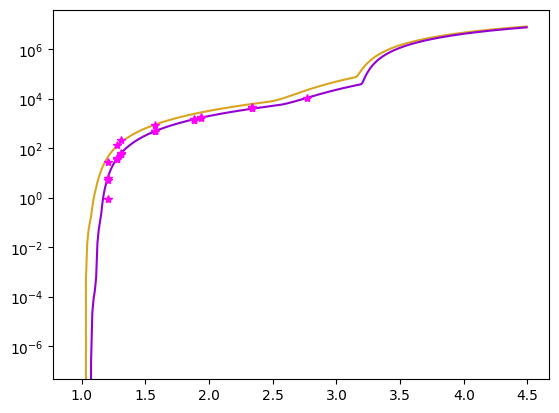

In [7]:
# plt.semilogy(hc/ephoton, 1e7/alphaCoeff, label='Total absorption')
plt.semilogy(ephoton, alphaCoeff, label='Total absorption')

plt.semilogy(ephoton, alphaLN2, label=f'Total absorption, T = {Tln2}K')

plt.semilogy(dfRT[colEph], dfRT[colSigma] * rho_Si, marker = "*", linestyle = "None", label='Experimental data')

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../o

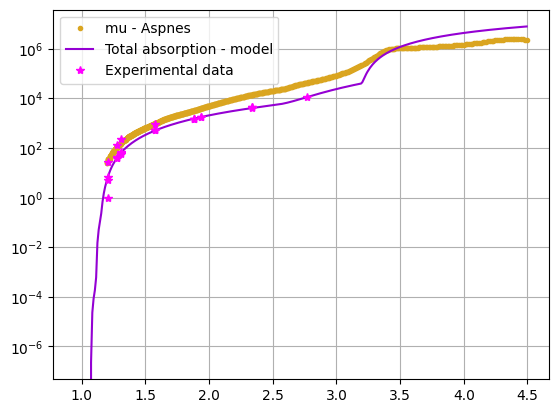

In [8]:
## comparing to n, k data

dh = OpticsData()
wlens = np.arange(hc/max(ephoton), hc/1.2, 1)
photon = PhotonInfo(wlen = wlens)

plt.semilogy(hc/photon.wlen, 1e7 * photon.muSi, marker = ".", linestyle="None", label='mu - Aspnes')

plt.semilogy(ephoton, alphaLN2, label='Total absorption - model')

plt.semilogy(dfRT[colEph], dfRT[colSigma] * rho_Si, marker = "*", linestyle = "None", label='Experimental data')

# plt.plot(hc/ephoton, alphaCoeff, label='Total absorption')
# plt.plot(dh.wlen, dh.k, label='k')

# plt.xlim(250, 1200)
# plt.ylim(1, 1e6)
plt.legend()
plt.grid()

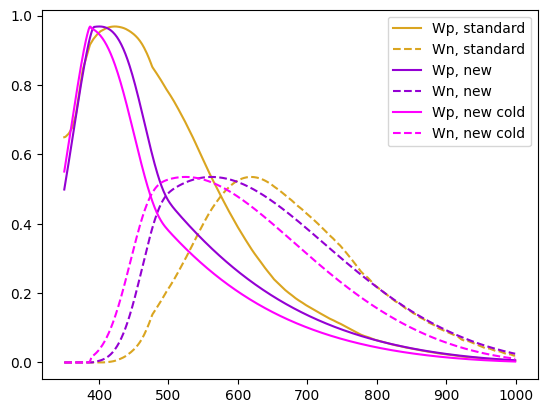

In [9]:
wlens = np.arange(350, 1000, 1)

photonStandard = PhotonInfo(wlen = wlens)

photonNew = PhotonInfo(wlen = wlens)
photonNew.muSi = alpha(E_gamma = hc/photonNew.wlen, T=300)[0] * 1e-7

photonNewCold = PhotonInfo(wlen = wlens)
photonNewCold.muSi = alpha(E_gamma = hc/photonNewCold.wlen, T=160)[0] * 1e-7

pn = PNJunction(tOxide = 17, dp_star = 4, Xpn=800, dw_star=4e3, pe = 1.0, ph = 0.4)

ms.ResetColorCycle()
col = ms.GetNextColor()
plt.plot(wlens, pn.calcWp(photonStandard), color = col, label='Wp, standard')
plt.plot(wlens, pn.calcWn(photonStandard), color = col, linestyle="--", label='Wn, standard')

col = ms.GetNextColor()
plt.plot(wlens, pn.calcWp(photonNew), color = col, label='Wp, new')
plt.plot(wlens, pn.calcWn(photonNew), color = col, linestyle="--", label='Wn, new')

col = ms.GetNextColor()

plt.plot(wlens, pn.calcWp(photonNewCold), color = col, label='Wp, new cold')
plt.plot(wlens, pn.calcWn(photonNewCold), color = col, linestyle="--", label='Wn, new cold')

plt.legend()
plt.show()
# plt.grid()

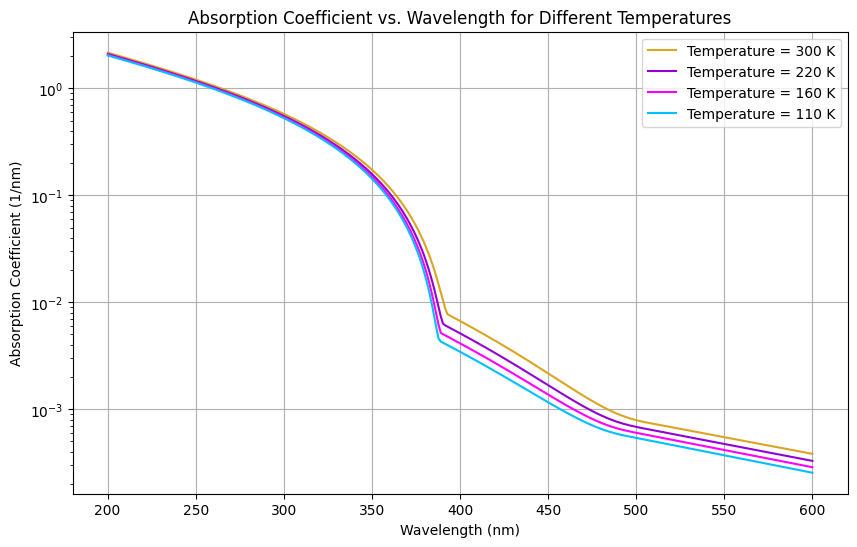

In [10]:
## plot alpha for different temperatures over full wlen range
plt.figure(figsize=(10, 6))

# plt.xlim(300, 800)
ePhotonZoom = np.arange(hc/600, hc/200, 0.01)

plotTemps = [300, 220, 160, 110]
for temp in plotTemps:
    alpha_temp, *_ = alpha(ePhotonZoom, temp, includeDirect=1, fixDirectBandGap=False)
    alpha_nm = alpha_temp * 1e-7
    plt.semilogy(hc/ePhotonZoom, alpha_nm, label=f'Temperature = {temp} K')


plt.xlabel('Wavelength (nm)')
plt.ylabel('Absorption Coefficient (1/nm)')
plt.title('Absorption Coefficient vs. Wavelength for Different Temperatures')
plt.legend()
plt.grid(True)
plt.show()

3.1551214488636363 3.1858251104100948
3.2 3.2
3.1551214488636363 3.1858251104100948
3.1551214488636363 3.1858251104100948
3.1551214488636363 3.1858251104100948
0.9315217784258967


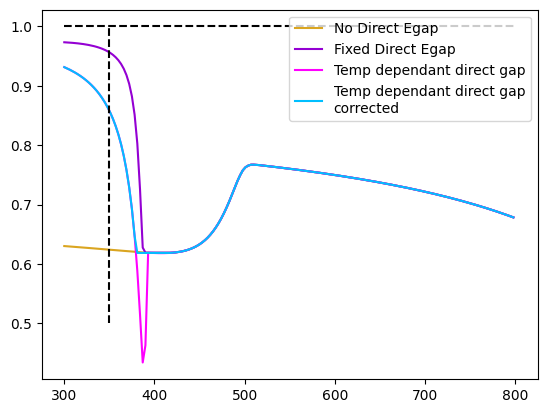

In [11]:
## make a function that calculates the relative change in alpha for a given temperature change. input is Tdata, Tnew, wlen
# tdata is the temperature the input optical data is taken at (not the PDE data)
# the PDE data is taken at Tnew
def calculate_relative_change(Tdata, Tnew, wlen, includeDirect = 1, fixDirectBandGap = False, numericalCorrection=True):
    ephoton = hc / wlen
    alpha_data, *_, EgapDirect_1 = alpha(E_gamma=ephoton, T=Tdata, includeDirect=includeDirect, fixDirectBandGap=fixDirectBandGap)
    alpha_new, *_, EgapDirect_2 = alpha(E_gamma=ephoton, T=Tnew, includeDirect=includeDirect, fixDirectBandGap=fixDirectBandGap)
    
    print(EgapDirect_1, EgapDirect_2)
    # relativeChange_fixedDirect = alpha(E_gamma=ephoton, T=Tnew, includeDirect=1, fixDirectBandGap=True)[0]/alpha(E_gamma=ephoton, T=Tdata, includeDirect=1, fixDirectBandGap=True)[0]
    
    relative_change = alpha_new / alpha_data
    if numericalCorrection:
        # fixing the low spike
        # if numericalCorrection and (fixDirectBandGap == False) and (includeDirect == True):
        Egap_1_wlen = hc/EgapDirect_1
        Egap_2_wlen = hc/EgapDirect_2
        rightLimit = max(Egap_1_wlen, Egap_2_wlen) # sorting so any T ordering works
        rightRelativeChange = relative_change[wlen > rightLimit][0]    
        relative_change[relative_change < rightRelativeChange] = rightRelativeChange
    return relative_change

wlens = np.arange(300, 800, 3)

plt.plot(wlens, calculate_relative_change(300, 160, wlens, 0), label='No Direct Egap')
plt.plot(wlens, calculate_relative_change(300, 160, wlens, 1, 1), label='Fixed Direct Egap')
plt.plot(wlens, calculate_relative_change(300, 160, wlens, 1, 0, 0), label='Temp dependant direct gap')
plt.plot(wlens, calculate_relative_change(300, 160, wlens, 1, 0, 1), label='Temp dependant direct gap\ncorrected')

print(max(calculate_relative_change(300, 160, wlens, 1, 0)))

plt.legend()
plt.hlines(1, 300, 800, linestyle='--', color='black')
plt.vlines([350], 0.5, 1., linestyle='--', color='black')

3.1551214488636363 3.1858251104100948
3.1551214488636363 3.1858251104100948


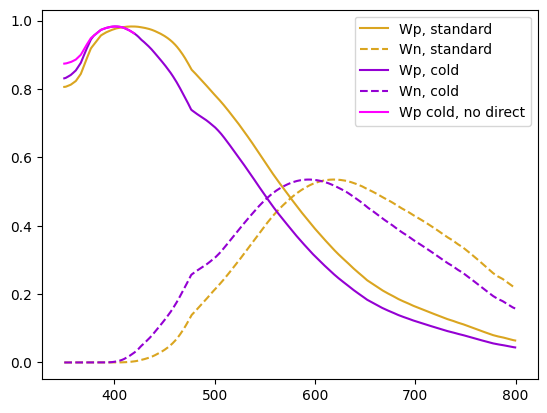

In [12]:
wlens = np.arange(350, 800, 0.5)

photonStandard = PhotonInfo(wlen = wlens)

photonCold = PhotonInfo(wlen = wlens)
photonCold.muSi = photonCold.muSi * calculate_relative_change(Tdata=300, Tnew=160, wlen=wlens)

photonNoDirect = PhotonInfo(wlen = wlens)
photonNoDirect.muSi = photonNoDirect.muSi * calculate_relative_change(Tdata=300, Tnew=160, wlen=wlens, includeDirect=0)


pn = PNJunction(tOxide = 17, dp_star = 2, Xpn=800, dw_star=4e3, pe = 1.0, ph = 0.4)
ms.ResetColorCycle()
col = ms.GetNextColor()
plt.plot(wlens, pn.calcWp(photonStandard), color = col, label='Wp, standard')
plt.plot(wlens, pn.calcWn(photonStandard), color = col, linestyle="--", label='Wn, standard')

col = ms.GetNextColor()
plt.plot(wlens, pn.calcWp(photonCold), color = col, label='Wp, cold')
plt.plot(wlens, pn.calcWn(photonCold), color = col, linestyle="--", label='Wn, cold')

col = ms.GetNextColor()
plt.plot(wlens[wlens < 420], pn.calcWp(photonNoDirect)[wlens < 420], color = col, label='Wp cold, no direct')
# plt.plot(wlens, pn.calcWn(photonNoDirect), color = col, linestyle="--", label='Wn, no direct')

plt.legend()
plt.show()
# plt.grid()

## the cold values, with no direct abs, actually increase Wp at low wavelength because there is decreased absorption with lower
# temperature, and it has a greater effect when the less temp dependant direct bandgap term is ignored